In [2]:
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp  # type: ignore[import]
from pathlib import Path
import matplotlib.pyplot as plt
from functools import partial
import pprint
# --------------------------------- Internal imports --------------------------------- #
from radiopyo_vec.physics.beam import ConstantBeam, ParticleBeam, PulsedBeam
from radiopyo_vec.sim_env import SimEnv
from radiopyo_vec.ode_solver import derive
import radiopyo_vec as rp

In [3]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager(csv=False)

In [4]:
def matprint(mat, fmt="g"):
    col_maxes = [max([len(("{:"+fmt+"}").format(x)) for x in col]) for col in mat.T]
    for x in mat:
        for i, y in enumerate(x):
            print(("{:"+str(col_maxes[i])+fmt+"}").format(y), end="  ")
        print("")

In [5]:
file = Path(rf"{rp.__path__[0]}\data\reactions_water.ron")
beam = PulsedBeam("e",10000, 500e-6, 250e-6, max_dose=100)
beam = ConstantBeam("e", 1e7, max_dose=500)
env = SimEnv.from_ron_file(file)

In [6]:
beam

ConstantBeam(particle='e', dose_rate=10000000.0, timer=Timer(period=inf, on_time=inf), max_dose=500, time_at_max_dose=5e-05, dose_per_pulse=inf, peak_dose_rate=10000000.0)

In [7]:
kwargs = {}
kwargs["max_step"] = np.inf
kwargs["first_step"] = 1e-10
kwargs["rtol"] = 1e-12
kwargs["method"] = "LSODA" # Possibilities: ["LSODA", "BDF", "Radau","DOP853","RK45"]
t_span = [1e-9, 1]
tlog = np.arange(-9, -2.9, step=0.1)
tspan = np.power(10, tlog)
tspan = np.append(tspan, np.arange(2e-3, t_span[1], step=1e-3))
y0 = env.initial_values()
ab_mat = env.make_acidBase_matrix()
ki_mat = env.make_kreaction_matrix()
Gi_mat = env.make_radiolytic_vector()
Enzi   = env.make_enzymatic_matrix()
print(y0)
#print("Initial values:")
#pprint.pprint(y0)

#print("\nAcid/Base:")
#pprint.pprint(ab_mat)

#print("\nKReactions:")
#print(ki_mat)

#print("\nRadiolytics: ")
#print(Gi_mat)

#print("\nEnzylmatic: ")
#print(Enzi)



[5.5e+07 1.0e-01 1.0e-01 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00
 0.0e+00 0.0e+00 0.0e+00 7.5e+01 0.0e+00 0.0e+00]


In [8]:
sol = solve_ivp(derive, t_span, y0, args=(ab_mat, ki_mat, Gi_mat, beam),t_eval=tspan, vectorized=False, **kwargs)
time, res = sol.t, sol.y

===> After A/B: [5.5e+01 1.0e-07 1.0e-07 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00
 0.0e+00 0.0e+00 0.0e+00 7.5e-05 0.0e+00 0.0e+00]
===> After A/B: [5.50000000e+01 1.00000000e-07 1.00000000e-07 2.90195897e-10
 3.65334989e-15 7.56576589e-11 1.50956876e-15 0.00000000e+00
 0.00000000e+00 2.90199550e-10 6.42584719e-11 4.87120674e-11
 7.50000000e-05 0.00000000e+00 0.00000000e+00]
===> After A/B: [5.50000000e+01 1.00000000e-07 1.00000000e-07 2.90195897e-10
 3.65334989e-15 7.56576589e-11 1.50956876e-15 4.05651465e-16
 5.10684938e-14 0.00000000e+00 7.31565949e-10 4.87120675e-11
 7.49999999e-05 0.00000000e+00 9.86404471e-20]
===> After A/B: [5.50000000e+01 1.00000000e-07 1.00000000e-07 2.90195897e-10
 3.65334990e-15 7.56576590e-11 1.50956876e-15 9.08025293e-16
 1.14313612e-13 2.91808995e-10 6.25338034e-11 4.87120685e-11
 7.49999999e-05 0.00000000e+00 9.86404469e-20]
===> After A/B: [5.50000000e+01 1.00000000e-07 1.00000000e-07 7.25489743e-11
 9.13337473e-16 1.89144147e-11 3.77392189e-16 

In [ ]:
env.species_labels()

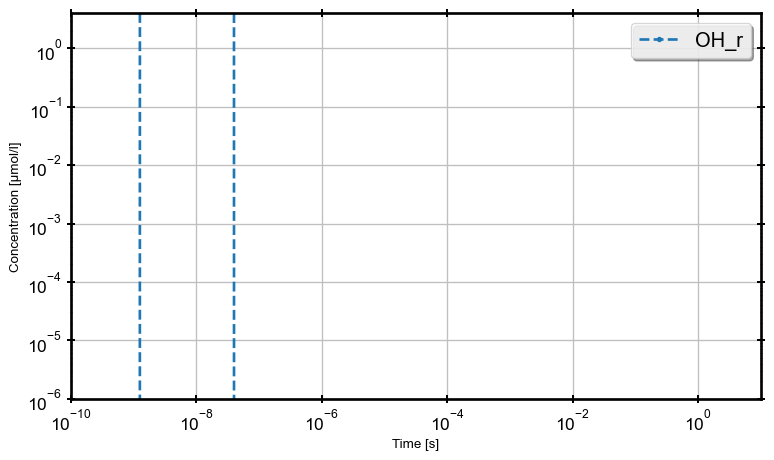

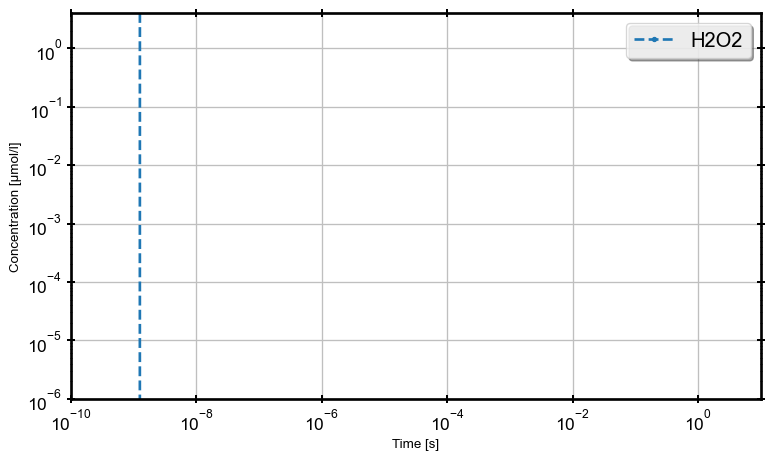

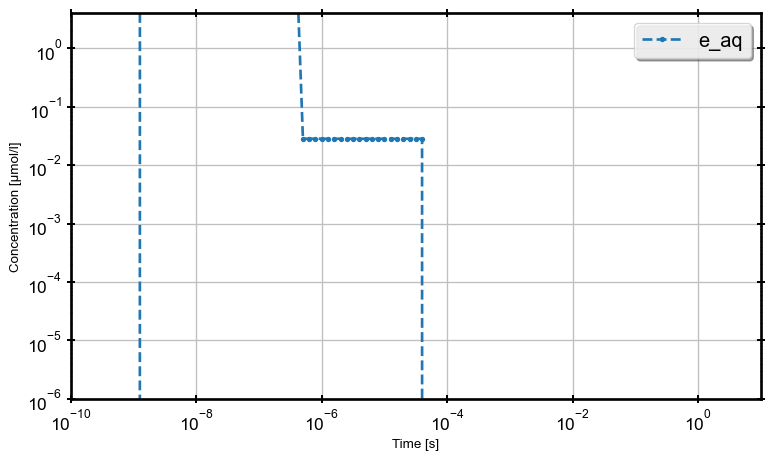

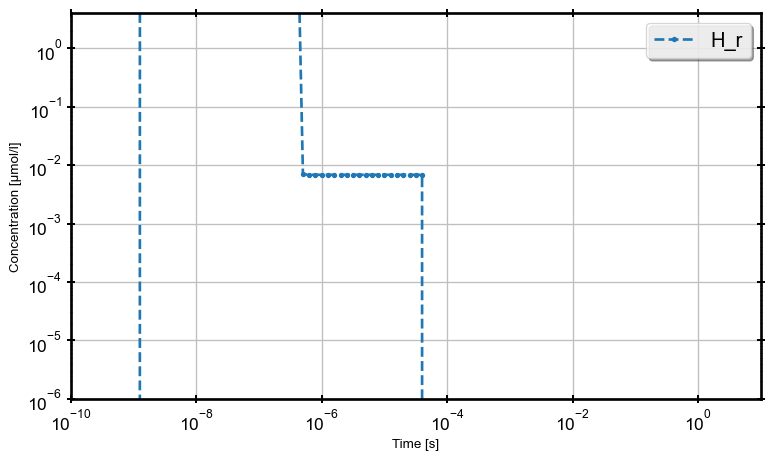

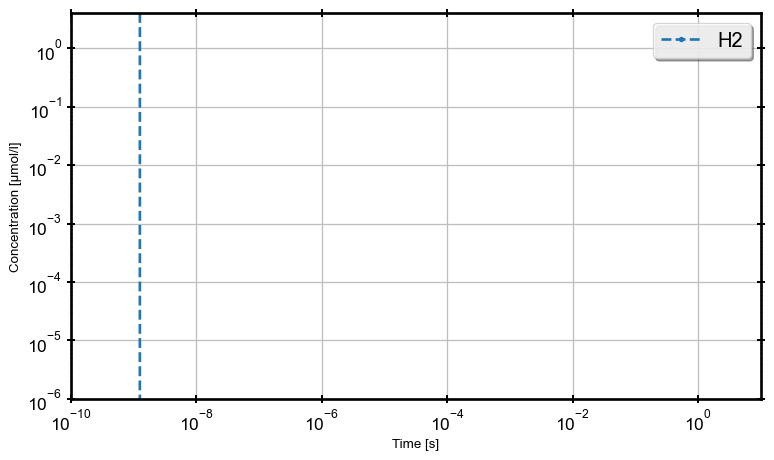

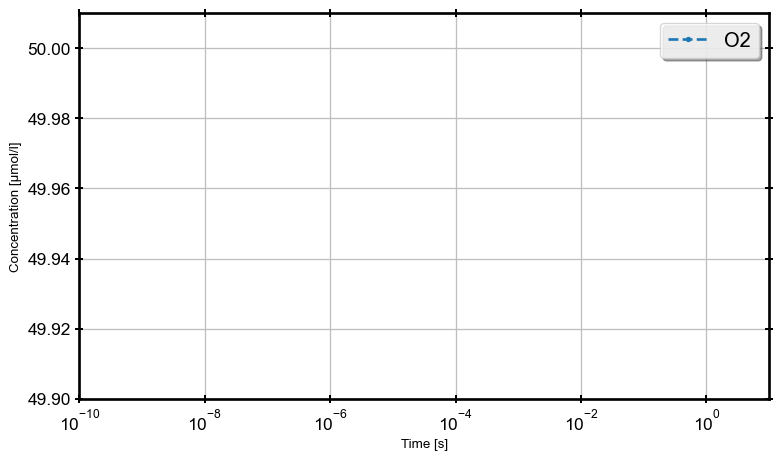

In [9]:
for (label, sp) in zip(env.species_labels(), res):
    if label not in ["OH_r", "H2O2", "e_aq", "H_r", "O2", "H2", "R_r", "ROO_r"]:
        continue
    with fig_man.open(f"{label.replace('/', '_')} CC evolution") as (fig, ax):
        sp = sp * 1e6
        if label=="O2":
            ax.semilogx(time , sp , label=label)
            ax.set_ylim([49.9, 50.01])
        else:
            ax.loglog(time , sp , label=label)
            ax.set_ylim(bottom=1e-6, top=4)
        ax.legend(loc='best')
        
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")

## Debug Acid/Base

In [13]:
y = np.ones(15)*10

In [10]:
matprint(ab_mat[1])

0  0  0  
0  0  0  
0  0  0  
1  0  0  
1  0  0  
0  1  0  
0  1  0  
0  0  1  
0  0  1  
0  0  0  
0  0  0  
0  0  0  
0  0  0  
0  0  0  
0  0  0  


In [11]:
ab_mat[0]

array([1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1], dtype=int8)

In [14]:
Ctot = np.matmul(y,ab_mat[1])
np.matmul(ab_mat[2], Ctot.T)

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.99997482e+01,
       2.51781913e-04, 1.99996010e+01, 3.99044501e-04, 1.57613677e-01,
       1.98423863e+01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00])

## Debug Radiolytic

In [12]:
dr = 1e7

In [13]:
Gi_mat*dr

array([0.        , 0.        , 0.        , 2.9019955 , 0.        ,
       0.75659168, 0.        , 0.        , 0.        , 2.9019955 ,
       0.64258472, 0.48712067, 0.        , 0.        , 0.        ])

In [17]:
for radio in env.reactions.radiolytic:
    print(radio, radio.kr()) # kr => mol/l/Gy

Radiolytic<e_aq, Ge:2.80> 2.9019955037534084e-07
Radiolytic<OH_r, Ge:2.80> 2.9019955037534084e-07
Radiolytic<H_r, Ge:0.62> 6.425847186882548e-08
Radiolytic<H2, Ge:0.47> 4.871206738443222e-08
Radiolytic<H2O2, Ge:0.73> 7.565916849071388e-08


## Debug K Reactions

In [11]:
y = env.initial_values()
dr = 1e7
y = np.ones_like(y) * 10
y

array([10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10.,
       10., 10.])

In [12]:
n = ki_mat[0]
n

2

In [13]:
u = np.append([1], np.tile(y, ki_mat[0]))
u

array([ 1., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10.,
       10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10.,
       10., 10., 10., 10., 10.])

In [18]:
x = np.multiply(ki_mat[1], u[:,None])
x[x==0]=1
np.prod(x,0)

array([1.90e+02, 5.50e+11, 1.10e+12, 3.00e+12, 2.20e+12, 2.30e+11,
       1.10e+12, 3.50e+11, 1.90e+12, 1.30e+12, 1.00e+02, 7.75e+11,
       7.00e+11, 2.20e+08, 9.00e+09, 2.10e+12, 1.00e+12, 5.50e+11,
       4.20e+09, 4.20e+08, 7.50e+11, 8.00e+11, 1.80e+07, 3.60e+11,
       6.00e+10])

In [12]:
np.matmul(ki_mat[2], np.prod(x,0).T)

array([ 0.000000e+00,  0.000000e+00,  0.000000e+00, -4.895602e+12,
       -2.619598e+12,  4.410000e+11, -1.100000e+12,  1.850000e+12,
       -2.600000e+11, -1.227978e+13, -6.225020e+12,  2.420800e+12,
       -3.500000e+12,  1.300000e+12,  3.600000e+11])

In [14]:
# Ri
matprint(ki_mat[1][:,:5])

19  5.5e+09  1.1e+10  3e+10  2.2e+10  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      1        0  
 0        0        0      0        1  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 1        1        1      1        1  
 0        0        1      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 0        0        0      0        0  
 0        1        0     

In [15]:
# Riy
matprint(ki_mat[2])

 0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  
 0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  
 0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  
 0   0   0  -1   0   0   1   1   0   0   1   0  -1   0   1   0   0  -2  -1  -1  -1  -1   1   0   0  
 0   0   0   0  -1   0   0   0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  -1  -1  -1  
 0   0   0   0   0   0  -1   0   0   0   0   0   0   0  -1   0   1   1   0   0   0   0   0   0   0  
 0   0   0   0   0   0   0  -1   0   0   0   0   0   0   0   0   0   0   0   0  -1   0   0   0   0  
 0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   1  -1   0   0   0   1   0   0   0   0  
 0   0   0   0   0   0   0   0   1  -1   0   0   0   0   0   0   0   0   0   0   0  -1   0   0  -1  
-1  -2  -1  -1  -1  -1  -1  -1  -1  -1   0   0   0   1   0   0   0   0   0   0   0   0   0 